Libraries imported successfully!

Dataset loaded successfully!

First 5 rows:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...      

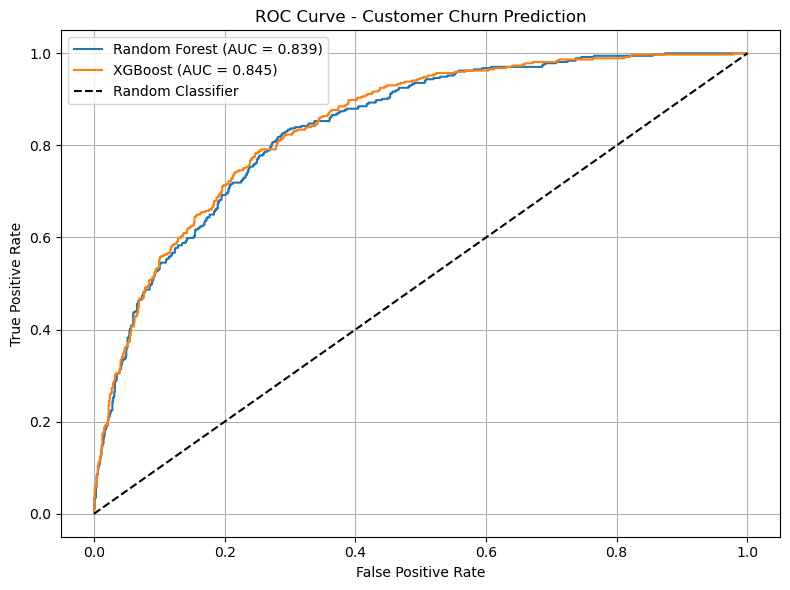

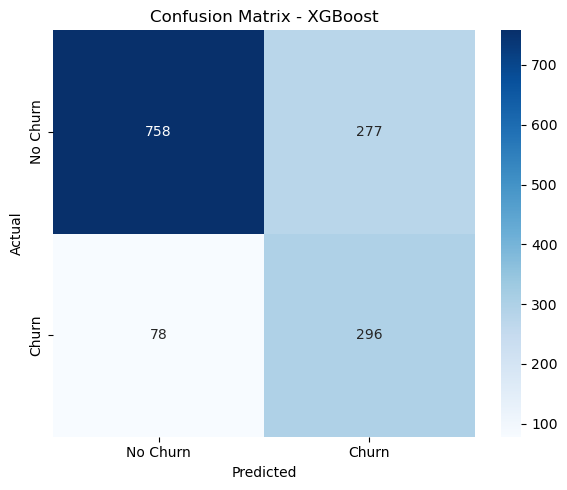

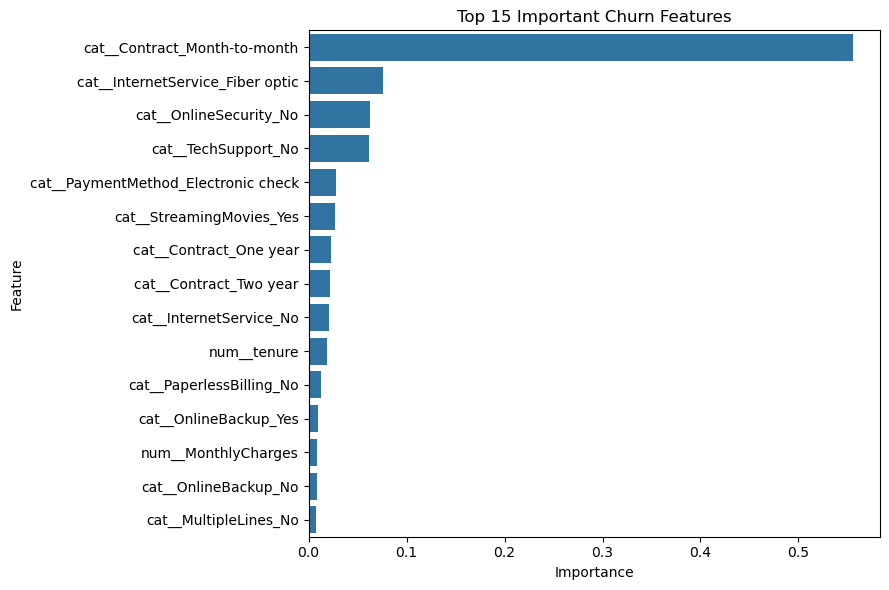


Results saved successfully!

CUSTOMER CHURN PREDICTION COMPLETED
Total customers: 7043
Total features: 19
Best model: XGBoost
Best ROC-AUC: 0.8448
ROC-AUC target above 80% achieved!

Generated files:
1. churn_model_results.csv
2. churn_feature_importance.csv
3. roc_curve.png
4. confusion_matrix.png
5. feature_importance.png

PROJECT COMPLETED SUCCESSFULLY!


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

url = (
    "https://raw.githubusercontent.com/IBM/"
    "telco-customer-churn-on-icp4d/master/data/"
    "Telco-Customer-Churn.csv"
)
df = pd.read_csv(url)
print("\nDataset loaded successfully!")
print("\nFirst 5 rows:")
print(df.head())
print("\nDataset shape:", df.shape)

df.drop("customerID", axis=1, inplace=True)
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df["Churn"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})
print("\nMissing values:")
print(df.isnull().sum())
print("\nChurn distribution:")
print(df["Churn"].value_counts())

X = df.drop("Churn", axis=1)
y = df["Churn"]
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()
print("\nNumerical features:")
print(numeric_features)
print("\nCategorical features:")
print(categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("\nPreprocessing pipeline created!")

negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("\nNon-churn customers:", negative_count)
print("Churn customers:", positive_count)
print("Class imbalance ratio:", round(scale_pos_weight, 2))

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

rf_params = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5]
}


xgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        scale_pos_weight=scale_pos_weight,
        n_jobs=-1
    ))
])

xgb_params = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [3, 5],
    "classifier__learning_rate": [0.05, 0.1]
}

models = {
    "Random Forest": (rf_pipeline, rf_params),
    "XGBoost": (xgb_pipeline, xgb_params)
}

results = []
trained_models = {}
predictions = {}
probabilities = {}

for name, (pipeline, params) in models.items():

    print("\nTraining:", name)

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=params,
        cv=3,
        scoring="roc_auc",
        n_jobs=-1,
        verbose=1
    )

    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_

    print("\nBest parameters:", grid.best_params_)
    print("Best CV ROC-AUC:", round(grid.best_score_, 4))

    # Predict classes and probabilities
    y_pred = best_model.predict(X_test)

    y_prob = best_model.predict_proba(X_test)[:, 1]

    trained_models[name] = best_model
    predictions[name] = y_pred
    probabilities[name] = y_prob

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    roc_auc = roc_auc_score(y_test, y_prob)

    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ]
)

print("\n========== MODEL PERFORMANCE ==========")
print(results_df.round(4).to_string(index=False))

best_index = results_df["ROC-AUC"].idxmax()
best_model_name = results_df.loc[
    best_index, "Model"
]

print("\nBest Model:", best_model_name)
best_predictions = predictions[best_model_name]
print("\nClassification Report:")
print(classification_report(
    y_test,
    best_predictions,
    target_names=["No Churn", "Churn"]
))

plt.figure(figsize=(8, 6))
for name, y_prob in probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob
    )
    auc_value = roc_auc_score(y_test, y_prob)
    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_value:.3f})"
    )
plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Classifier"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("roc_curve.png")
plt.show()

cm = confusion_matrix(
    y_test,
    best_predictions
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - " + best_model_name)
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

best_pipeline = trained_models[best_model_name]
feature_names = (
    best_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)
feature_importances = (
    best_pipeline
    .named_steps["classifier"]
    .feature_importances_
)
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
})
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(15)
plt.figure(figsize=(9, 6))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)
plt.title("Top 15 Important Churn Features")
plt.tight_layout()
plt.savefig("feature_importance.png")
plt.show()
results_df.to_csv(
    "churn_model_results.csv",
    index=False
)
importance_df.to_csv(
    "churn_feature_importance.csv",
    index=False
)
print("\nResults saved successfully!")
print("\n=================================")
print("CUSTOMER CHURN PREDICTION COMPLETED")
print("======================================")
print("Total customers:", len(df))
print("Total features:", X.shape[1])
print("Best model:", best_model_name)
best_auc = results_df.loc[
    best_index, "ROC-AUC"
]

print("Best ROC-AUC:", round(best_auc, 4))

if best_auc >= 0.80:
    print("ROC-AUC target above 80% achieved!")
else:
    print("ROC-AUC target above 80% not achieved.")
    print("Try additional feature engineering and tuning.")

print("\nGenerated files:")
print("1. churn_model_results.csv")
print("2. churn_feature_importance.csv")
print("3. roc_curve.png")
print("4. confusion_matrix.png")
print("5. feature_importance.png")
print("\nPROJECT COMPLETED SUCCESSFULLY!")

In [1]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.
